# Quantum Density Functional Theory
The ground state energy of a given sytem can be obtained by solving the Kohn-Sham (KS) equation.
$$
\left( \hat{T} + \hat{V}^{\mathrm{KS}}[n] \right)\, \lvert \Phi^{\mathrm{KS}} \rangle = E^{\mathrm{KS}} \, \lvert \Phi^{\mathrm{KS}} \rangle, \tag{1}
$$
Here $\hat{T}$ is the kinetic energy operator, $\lvert \Phi^{\mathrm{KS}} \rangle$ is a single Slater determinant and
$$
\hat{V}^{\mathrm{KS}}[n] = \hat{V}^{ext} + \hat{V}^{H}[n] + \hat{V}^{xc}[n], \tag{2}
$$
is the density-dependent KS potential operator. It contains the external potential $V^{ext}(\vec{r})$, i.e. the ion-electron interation, the trivial Hartree potential $\hat{V}^{H}[n](\vec{r})$ and exchange-correlation potential $\hat{V}^{xc}[n](\vec{r})$.
The Kohn-Sham Hamiltonian depends on the electronic density,
$$
n(\vec{r}) = \sum_{k=1}^{N_{occ}} \langle \vec{r} \lvert \phi_k \rangle \langle \phi_k \lvert \vec{r} \rangle, \tag{3}
$$
where $\{\phi_k (\vec{r})\}$ are the KS orbitals in $\lvert \Phi^{\mathrm{KS}} \rangle$, $N_{occ}$ denotes the number of occupied spin-orbitals and $\vec{r}$ the position vector. The electronic density is used to compute a new KS potential, so that equation (1) and (3) are self-consistently and iteratively solved until convergence is reached.

# Mapping the KS Hamiltonian onto qubits

The KS orbitals are obtained by solving the one-particle Kohn-Sham Hamiltonian (expressed in a basis of orthogonal atomic orbitals $\lbrace \chi_i \rbrace$),
$$
\hat{h}^{KS} = \sum_{ij}^N h^{KS}_{ij} (\hat{c}^\dagger_i \hat{c}_j + \text{h.c.} ), ~~ \hat{h}^{KS} \ket{\phi_k} = \varepsilon_k \ket{\phi_k}
$$
where $h^{KS}_{ij}$ are the element of the one-particle Fock matrix of dimension $N \times N$, mapped onto $M = \mathcal{O}(\log_2 N)$ qubits using binary mapping. 
Within this qubit-efficient mapping, each orbital of computational basis-set $\ket{\chi_i}$ is associated to a binary string $\lvert i \rangle$ (representing the integer $i$),
$$
\hat{h}^{KS} = \sum_{i=0, j=0}^{2^{M}-1} h^{KS}_{ij} \lvert i \rangle \langle j \lvert.
$$

# Self-consistent conditions on quantum device
Within the ensemble-VQE, we consider qn ensemble of $N_{occ}$ states,
$$
\lvert \phi_k(\theta) \rangle = \hat{U}(\theta) \, \lvert \phi_k \rangle, \quad 1 \le k \le N_{occ}
$$
where $\{\phi_k\}$ is an orthonormal basis. 
$$
E^{ens} = \min_{\theta} \, \{ \, \sum_{k=1}^{N_{occ}} w_k \, \langle \phi_k(\theta) \lvert \hat{h}^{KS} \rvert \phi_k(\theta) \rangle\}
$$
here $w_k = 1/k$ called equi-ensemble or $w_k = (2N_{occ}-1-2k)/N_{occ}^2$ called weighted ensemble. 
The KS energy will be,
$$
E^{KS} \approx E^{KS} (\theta^*) =  \sum_{k=1}^{N_{occ}} \, \langle \phi_k(\theta^*) \lvert \hat{h}^{KS} \rvert \phi_k(\theta^*) \rangle
$$
and the density is calculated with the following relation:
$$
n(\vec{r}) = \sum_{i=1, j=1}^{N} \sum_{k=1}^{N_{occ}} \langle \vec{r} \lvert \chi_i \rangle \langle \chi_i \lvert \phi_k \rangle \langle \phi_k \lvert \chi_j \rangle \langle \chi_j \lvert \vec{r} \rangle
$$
$$
= \sum_{i=1, j=1}^{N} \langle \vec{r} \lvert \chi_i \rangle \langle \chi_j \lvert \vec{r} \rangle \sum_{k=1}^{N_{occ}} \phi_k(i)\phi_k(j),
$$
with $\phi_k(i) = \langle \chi_i \vert \phi_k \rangle \equiv \langle i \vert \phi_k \rangle$.
The product $\phi_k(i)\phi_k(j)$ can be estimated directly by repeated measurements of the operator
$\vert i  \rangle\langle j\vert + \vert j \rangle\langle i\vert$ (after transformation into a linear combination of Pauli-strings)
on the prepared state $\ket{\phi_k(\theta^*)}$, leading to $2Re(\phi_k(i)\phi_k(j))$. The elements $ \langle \vec{r} \lvert \chi_i \rangle $ are known classically.

# Notes
- This is a statevector simulation on the perceval photonic device using Dual-rail encoding.
- The total number of iterations will be 5. There will be a new hamiltonian and density matrix for each iteration.

# H and D of each iteration for Experimental
Initial guess Density in AO basis: $D^{guess}$

\begin{bmatrix}
0.83809843 & 0.09798506 & 0.09310489 & 0.03949446 \\
0.09798506 & 0.83809843 & 0.03949446 & 0.09310489 \\
0.09310489 & 0.03949446 & 0.94192929 & 0.01574639 \\
0.03949446 & 0.09310489 & 0.01574639 & 0.94192929
\end{bmatrix}


$$
H^1 = 0.10658543\, II
     - 0.26276814\, IX
     - 0.42591697\, XI  + 0.10364115\, XX
     + 0.08623429\, ZI
     - 0.23846842\, ZX 
$$
  
 --------------------------------------------------
Density in OAO basis: $D^1$:
\begin{bmatrix}
0.4759294  & 0.23749211 & 0.43914487 & 0.01303429 \\
0.23749211 & 0.47620558 & 0.01285079 & 0.43916532 \\
0.43914487 & 0.01285079 & 0.52416984 &-0.23749203 \\
0.01303429 & 0.43916532 &-0.23749203 & 0.52369519
\end{bmatrix}


$$
H^2 =
0.1223350050\, II
- 0.2642415780\, IX
+ 0.0001097028\, IZ
- 0.4246506020\, XI
+ 0.1040782710\, XX
- 0.0000033944\, XZ
+ 0.0000003032\, YY
+ 0.0758960404\, ZI
- 0.2398195410\, ZX
- 0.0000765068\, ZZ
$$
  
---------------------------------------------------
Density in OAO basis: $D^2$:
\begin{bmatrix}
0.48564009 & 0.24193928 & 0.43726035 & 0.00790951 \\
0.24193928 & 0.48561452 & 0.00799556 & 0.43725795 \\
0.43726035 & 0.00799556 & 0.51431229 &-0.24193928 \\
0.00790951 & 0.43725795 &-0.24193928 & 0.51443309
\end{bmatrix}


$$
H^3 =
0.1250140280\, II
- 0.2641253660\, IX
+ 0.0000161579\, IZ
- 0.4247400740\, XI
+ 0.1039192530\, XX
- 0.0000011404\, XZ
+ 0.0000003313\, YY
+ 0.0798526176\, ZI
- 0.2397743090\, ZX
- 0.0000167338\, ZZ
$$
  
  ---------------------------------------------------

 Density in OAO basis: $D^3$:
\begin{bmatrix}
0.4820981  & 0.24084761 & 0.43769377 & 0.00980395 \\
0.24084761 & 0.48221701 & 0.00983211 & 0.43769798 \\
0.43769377 & 0.00983211 & 0.51788641 &-0.24084762 \\
0.00980395 & 0.43769798 &-0.24084762 & 0.51779848
\end{bmatrix}

 
$$
H^4 =
0.1250073290\, II
- 0.2641216850\, IX
+ 0.0000035496\, IZ
- 0.4247446350\, XI
+ 0.1039183490\, XX
- 0.0000015862\, XZ
+ 0.0000006970\, YY
+ 0.0798906623\, ZI
- 0.2397709510\, ZX
- 0.0000159319\, ZZ
$$
  
  ---------------------------------------------------
  
  Final density: 
Density in OAO basis: $D^4$:
\begin{bmatrix}
0.48215912 & 0.24086493 & 0.43768692 & 0.00979544 \\
0.24086493 & 0.48206822 & 0.00989086 & 0.43768106 \\
0.43768692 & 0.00989086 & 0.51778836 &-0.24086492 \\
0.00979544 & 0.43768106 &-0.24086492 & 0.51798429
\end{bmatrix}


# Circuits
![my Plot](H4_1.png)
![my Plot](H4_2.png)

In [1]:
import numpy as np
import scipy as sp
from pyscf import gto, scf
import perceval as pcvl
from qiskit.quantum_info import Pauli, PauliList, Statevector, SparsePauliOp, Operator
from qlass.quantum_chemistry.hamiltonians import transformation_Hmatrix_Hqubit, sparsepauliop_dictionary
from qlass.vqe.ansatz import list_of_ones
from qlass.utils import photon_to_qubit_unitary
from qiskit.circuit.library import n_local
from perceval.algorithm import Sampler
from qiskit import QuantumCircuit, transpile
from perceval.converters import QiskitConverter
from perceval.components import catalog
from perceval.simulators import Simulator
from perceval import BasicState
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import warnings
warnings.filterwarnings('ignore')

/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


# This part is dedicated for Mapping

In [2]:
'''decompose operator to pauli'''
pauli_matrices = {
    'I': np.array([[1, 0], [0, 1]]),
    'X': np.array([[0, 1], [1, 0]]),
    'Y': np.array([[0, -1j], [1j, 0]]),
    'Z': np.array([[1, 0], [0, -1]]),
}

# Generate all tensor products of Pauli matrices for n qubits
def generate_pauli_strings(n):
    from itertools import product
    labels = ['I', 'X', 'Y', 'Z']
    pauli_strings = [''.join(p) for p in product(labels, repeat=n)]
    return pauli_strings


# Create a dictionary to map Pauli labels to their ndarray representations
def create_pauli_to_matrix(n):
    pauli_strings = generate_pauli_strings(n)
    pauli_to_matrix = {}
    for label in pauli_strings:
        matrix = pauli_matrices[label[0]]
        for char in label[1:]:
            matrix = np.kron(matrix, pauli_matrices[char])
        pauli_to_matrix[label] = matrix
    return pauli_to_matrix


# Function to decompose an operator into Pauli strings
def decompose_operator_to_pauli_list(operator):
    nqubits = int(np.log2(operator.dim[0]))  # Number of qubits
    pauli_to_matrix = create_pauli_to_matrix(nqubits)
    pauli_list = {}
    dim = operator.dim[0]

    # Iterate over all possible Pauli matrices
    for pauli_str, pauli_matrix in pauli_to_matrix.items():
        coeff = np.trace(np.dot(operator.data, pauli_matrix)) / dim

        # Check if coefficient is non-zero
        if np.abs(coeff) > 1e-10:
            pauli_list[pauli_str] = pauli_list.get(pauli_str, 0) + coeff

    # Convert to a list of tuples (Pauli object, coefficient)
    pauli_list = [(Pauli(pauli_str), coeff) for pauli_str, coeff in pauli_list.items()]
    return pauli_list

P = [Pauli('X'), Pauli('Y'), Pauli('Z'), Pauli('I')]
X, Y, Z, I = Operator(P[0]).data, Operator(P[1]).data, Operator(P[2]).data, Operator(P[3]).data

def list_Pauli_to_SparsePauliOp(list_pauli: list):

    pauli_list: list[Pauli] = []
    pauli_coeff: list[float] = []
    for lines in list_pauli:
        pauli_list.append(lines[0])
        pauli_coeff.append(lines[1])
    return SparsePauliOp(pauli_list, coeffs=pauli_coeff)


def transformation_Hmatrix_Hqubit(Hmatrix,nqubits):

    """
    This function transforms the Hamiltonian matrix into the qubit Hamiltonian.
    Each element of the Hamiltonian is defined in the basis of bitstring configurations,
    i.e. | 0000 ... 0 >, | 0000 ... 1 >, etc. Each value "1" corresponds to a qubit excitation
    that is given by the operation S^+.
    """
    H_qubit = 0.
    IJ_op_list = [] # list of operators for ( |phi_I><phi_J| + h.c. )
    full_pauliop_list = [] # list of pauli strings operator to measure the Hamiltonian and c_i c_j product for the density.
    full_pauli_list = [] # list of pauli strings to measure the Hamiltonian and c_i c_j product for the density.

    for i in range(len(Hmatrix[0])):
        for j in range(len(Hmatrix[0])):

            # < J |
            # i = | I >
            # j = < J |
            IJ_op = np.eye(2 ** nqubits)


            # First convert the integers into bitstrings:
            bitstring_i = bin(i)[2:].zfill(nqubits)
            bitstring_j = bin(j)[2:].zfill(nqubits)

            for qubit in range(nqubits):
                if int(bitstring_i[qubit]) == 0 and int(bitstring_j[qubit]) == 0:
                       op_1 = (((X + 1j*Y)@(X - 1j*Y))/4.)
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op
                elif int(bitstring_i[qubit]) == 0 and int(bitstring_j[qubit]) == 1:
                       op_1 = (X + 1j*Y)/2.
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op
                elif int(bitstring_i[qubit]) == 1 and int(bitstring_j[qubit]) == 0:
                       op_1 = (X - 1j*Y)/2.
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op
                elif int(bitstring_i[qubit]) == 1 and int(bitstring_j[qubit]) == 1:
                       op_1 = (((X - 1j * Y) @ (X + 1j * Y)) / 4.)
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op

                # Add the element of the Hamiltonian matrix to H_qubit
            H_qubit += Hmatrix[i, j] * IJ_op

            # Calculate the adjoint of IJ_op and add it
            IJ_op_adjoint = IJ_op.transpose()

            IJ_op = IJ_op + IJ_op_adjoint

            IJ_op = decompose_operator_to_pauli_list(IJ_op)
            if j < i+1:
                IJ_op_list.append(IJ_op)
                for num_pauli in range(len(IJ_op)):
                    pauli_string = IJ_op[num_pauli]
                    if pauli_string[0] not in full_pauli_list:
                        full_pauliop_list.append(SparsePauliOp(pauli_string[0]))
                        full_pauli_list.append(pauli_string[0])
    H_qubit = decompose_operator_to_pauli_list(H_qubit)
    H_qubit = list_Pauli_to_SparsePauliOp(H_qubit)
    # IJ_op_list = list_Pauli_to_SparsePauliOp(IJ_op_list)
    IJ_op_list_sp = []
    for list_values in IJ_op_list:
        IJ_op_list_sp.append(list_Pauli_to_SparsePauliOp(list_values))

    IJ_op_list = IJ_op_list_sp

    return H_qubit, IJ_op_list, full_pauliop_list, full_pauli_list

# Circuit preparation using binarystring representation

In [3]:
def circuit(nqubit, n_states, lp, layers=1):

    initial_circuits = []

    if nqubit is None:
        num_qubits = 2
    else:
        num_qubits = nqubit
    for _i in range(n_states):
        initial_circuits += [QuantumCircuit(num_qubits)]
    """Initial states"""
    for state in range(n_states):  # binarystring representation of the integer
        for i in list_of_ones(state, num_qubits):
            initial_circuits[state].x(i)

    circuits = []
    for state in range(n_states):
        ansatz = n_local(
            num_qubits=num_qubits,
            rotation_blocks="ry",
            entanglement_blocks="cx",
            entanglement="linear",
            reps=layers,
            insert_barriers=False,
        )
        # Prepend the initial state
        circuit = QuantumCircuit(num_qubits)
        circuit.compose(initial_circuits[state], inplace=True)
        circuit.compose(ansatz, inplace=True)
        circuits.append(circuit)

    """Assign parameters"""
    intial_states = []
    for c in range(len(initial_circuits)):
        sv = Statevector.from_instruction(initial_circuits[c])
        index = list(sv.data).index(1 + 0j)  # position of the "1"
        bitstring = format(index, f"0{sv.num_qubits}b")
        bits_list = [int(b) for b in bitstring]
        intial_states.append(pcvl.LogicalState(bits_list))
    circuits = [c.assign_parameters(lp) for c in circuits]
    ansatz_transpiled = [
        transpile(c, basis_gates=["u3", "cx"], optimization_level=3) for c in circuits
    ]
    q_converter = QiskitConverter(backend_name="SLOS")
    processors = [q_converter.convert(at, use_postselection=True) for at in ansatz_transpiled]

    p_processors = [p.with_input(input_state=ist) for p, ist in zip(processors, intial_states, strict=False)]


    return processors

# Running PySCF to extract H, S, and D

In [4]:
def input_pyscf(n_hydrogens: int = 2, R: float = 1.2, XC_functional: str = 'SVWN',
):
    geometry = []
    numberof_qubits = int(np.log2(n_hydrogens))


    for d in range(n_hydrogens // 2):
        geometry.append(("H", (0.0, 0.0, -(R / 2.0 + d * R))))
        geometry.append(("H", (0.0, 0.0, +(R / 2.0 + d * R))))

    molecule = gto.M(atom=geometry, basis="sto-3g")
    mf = scf.RKS(molecule)
    mf.xc = 'SVWN'
    # mf.max_cycle = 1
    mf.verbose = 4
    mf.scf()
    H_core = mf.get_hcore()
    S_AO = mf.get_ovlp()
    D_AO = mf.get_init_guess()
    # D_AO = mf.make_rdm1()
    E_nuc = mf.energy_nuc()
    F_AO = mf.get_fock(dm=D_AO)  # H_core + V_HF
    # F_AO = mf.get_fock()  # H_core + V_HF

    mo_energy = mf.mo_energy

    AO_kinetic = molecule.intor("int1e_kin")
    AO_potential = molecule.intor("int1e_nuc")  # V_nuc

    # Kinetic + nuclear
    E_T = np.einsum('pq,pq->', D_AO, AO_kinetic)
    E_V = np.einsum('pq,pq->', D_AO, AO_potential)

    # XC energy from grid
    Exc = mf.energy_elec(dm=D_AO)[1]  # E_Hartree + E_XC

    # Total electronic energy
    E_elec = E_T + E_V + Exc

    # Total energy
    E_tot = E_elec + E_nuc

    print(f"Energy from guess density: {E_tot:.8f}")
    return D_AO, S_AO, AO_kinetic, AO_potential, E_nuc, mf, numberof_qubits

# Calculating the expectation values from statevectors

In [5]:
def mesurements(H, proc):
    tr =0.
    be = proc.backend
    cir = proc.linear_circuit()
    int_st = proc.input_state
    be.set_circuit(cir)
    be.set_input_state(input_state=int_st)
    st_vec = be.prob_amplitude(output_state=int_st)
    from itertools import product

    basis_states = list(product(range(2), repeat=int_st.m))
    # Filter for dual-rail encoding (exactly one photon per qubit pair)
    dual_rail_basis = []
    for state in basis_states:
        if (state[0] + state[1] == 1 and
                state[2] + state[3] == 1 and
                sum(state[4:]) == 0):
            dual_rail_basis.append(state)

    statevector = []
    for state in dual_rail_basis:
        fock_state = BasicState(state)
        amp = be.prob_amplitude(output_state=fock_state)
        statevector.append(amp)
    norm = sum(abs(a) ** 2 for a in statevector) ** 0.5
    statevector = [a / norm for a in statevector]
    st = np.array(statevector)
    energy = np.vdot(st, H @ st)

    return energy.real

In [6]:
def sparsepauliop_to_dict(sp_op) -> dict:
    """
    Convert a SparsePauliOp into a dictionary mapping Pauli strings to coefficients.
    """
    # sp_op.paulis is a list of Pauli objects, sp_op.coeffs is a numpy array
    pauli_strings = [p.to_label() for p in sp_op.paulis]
    coeffs = []
    for c in sp_op.coeffs:
        if abs(c.imag) < 1e-12:   # negligible imaginary part
            coeffs.append(float(c.real))  # cast to plain Python float
        else:
            coeffs.append(complex(c))  # keep complex if significant
    return dict(zip(pauli_strings, coeffs))

In [7]:
def _callback(param, H):
    cost = cost_function_statevector(param, H)
    processors = circuit(2, 2, layers=1, lp=param)
    trH = 0.
    for state in range(2):
        trH += mesurements(Ham, processors[state])
    vqe_cost.append(cost)
    vqe_tr.append(trH)

In [8]:
def plot_vqe(cost, trace, energy_classic, iteration):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(cost, label="cost")
    ax.plot(trace, label="trace")
    ax.axhline(y=energy_classic, ls="--", color="red", label="classical diag")
    ax.set_ylabel('Energy (hartree)', fontsize=16)
    ax.set_xlabel('VQE Iteration', fontsize=16)
    ax.tick_params(axis='both', labelsize=16)
    ax.legend(fontsize=16, loc="lower left")
    ax.set_title(f"ensemble VQE | SCF iteration: {iteration}", fontsize=16)
    sub_ax = inset_axes(
        parent_axes=ax,
        width="40%",
        height="40%",
        borderpad=1  # padding between parent and inset axes
    )
    sub_ax.plot(trace - energy_classic, color="green", label="error")
    sub_ax.set_yscale('log')
    sub_ax.set_ylabel('Error (hartree)', fontsize=16)
    sub_ax.set_xlabel('Iteration', fontsize=16)
    sub_ax.tick_params(axis='both', labelsize=16)
    sub_ax.legend(fontsize=16)
    plt.show()

In [17]:
def plot_density(density, title="Electron Density in OAO basis"):
    plt.figure(figsize=(6,5))
    plt.imshow(density, cmap="plasma")
    for i in range(density.shape[0]):
        for j in range(density.shape[1]):
            plt.text(j, i, f"{density[i, j]:.6f}", ha='center', va='center', color='red')
    plt.colorbar(label="Density")
    plt.title(title)
    plt.xlabel(r"$x_2$ grid index")
    plt.ylabel(r"$x_1$ grid index")
    plt.show()

In [18]:
def cost_function_statevector(param, H):
    processors = circuit(2, 2, layers=1, lp=param)
    w = 1/len(processors)
    cost = 0.
    tr =0.
    for p in processors:
        be = p.backend
        cir = p.linear_circuit()
        int_st = p.input_state
        be.set_circuit(cir)
        be.set_input_state(input_state=int_st)
        st_vec = be.prob_amplitude(output_state=int_st)
        from itertools import product

        basis_states = list(product(range(2), repeat=int_st.m))
        # Filter for dual-rail encoding (exactly one photon per qubit pair)
        dual_rail_basis = []
        for state in basis_states:
            if (state[0] + state[1] == 1 and
                    state[2] + state[3] == 1 and
                    sum(state[4:]) == 0):
                dual_rail_basis.append(state)

        statevector = []
        for state in dual_rail_basis:
            fock_state = BasicState(state)
            amp = be.prob_amplitude(output_state=fock_state)
            statevector.append(amp)
        norm = sum(abs(a) ** 2 for a in statevector) ** 0.5
        statevector = [a / norm for a in statevector]
        st = np.array(statevector)
        energy = np.vdot(st, H @ st)
        cost += w * energy.real
        tr += energy.real

    return cost

In [19]:
#Input preparation: PySCF
Number_of_Hydrogen = 4
bond_length = 0.784
XC_function = "SVWN"

# QDFT inputs
SCF_maxiter = 20
E_conv = 1e-5
D_conv = 1e-4

D_AO, S_AO, AO_kinetic, AO_potential, E_nuc, mf, n_qubits = input_pyscf(Number_of_Hydrogen, bond_length, XC_function)
n_orbs = 2 ** n_qubits
# Compute the inverse square root of the overlap matrix S
S_eigval, S_eigvec = np.linalg.eigh(S_AO)
S_sqrt_inv = S_eigvec @ np.diag((S_eigval) ** (-1.0 / 2.0)) @ S_eigvec.T

Etot = 0.0
F_list = []
DIIS_error = []
params = np.random.rand(4)
print("-"*25)
print("ensemble-VQE calculation starts ...")



******** <class 'pyscf.dft.rks.RKS'> ********
method = RKS
initial guess = minao
damping factor = 0
level_shift factor = 0
DIIS = <class 'pyscf.scf.diis.CDIIS'>
diis_start_cycle = 1
diis_space = 8
diis_damp = 0
SCF conv_tol = 1e-09
SCF conv_tol_grad = None
SCF max_cycles = 50
direct_scf = True
direct_scf_tol = 1e-13
chkfile to save SCF result = /tmp/tmp80lv4v1q
max_memory 4000 MB (current use 402 MB)
XC library pyscf.dft.libxc version 7.0.0
    S. Lehtola, C. Steigemann, M. J.T. Oliveira, and M. A.L. Marques.,  SoftwareX 7, 1–5 (2018)
XC functionals = SVWN
    P. A. M. Dirac.,  Math. Proc. Cambridge Philos. Soc. 26, 376 (1930)
    F. Bloch.,  Z. Phys. 57, 545 (1929)
    S. H. Vosko, L. Wilk, and M. Nusair.,  Can. J. Phys. 58, 1200 (1980)
small_rho_cutoff = 1e-07
Set gradient conv threshold to 3.16228e-05
Initial guess from minao.
init E= -1.93605433385552
  HOMO = -0.25182568098729  LUMO = 0.200239687458301
cycle= 1 E= -2.16253338078866  delta_E= -0.226  |g|= 0.0268  |ddm|= 1.42
  HO

# QDFT iterations

Printing Hamiltonian: 
 SparsePauliOp(['II', 'IX', 'XI', 'XX', 'ZI', 'ZX'],
              coeffs=[ 0.10658543+0.j, -0.26276814+0.j, -0.42591697+0.j,  0.10364115+0.j,
  0.08623429+0.j, -0.23846842+0.j])
optimized parameters: [ 1.07504906  1.57058771 -0.05444288  3.14080227]
Energy from classical diagonalazation: -0.7644308027227094


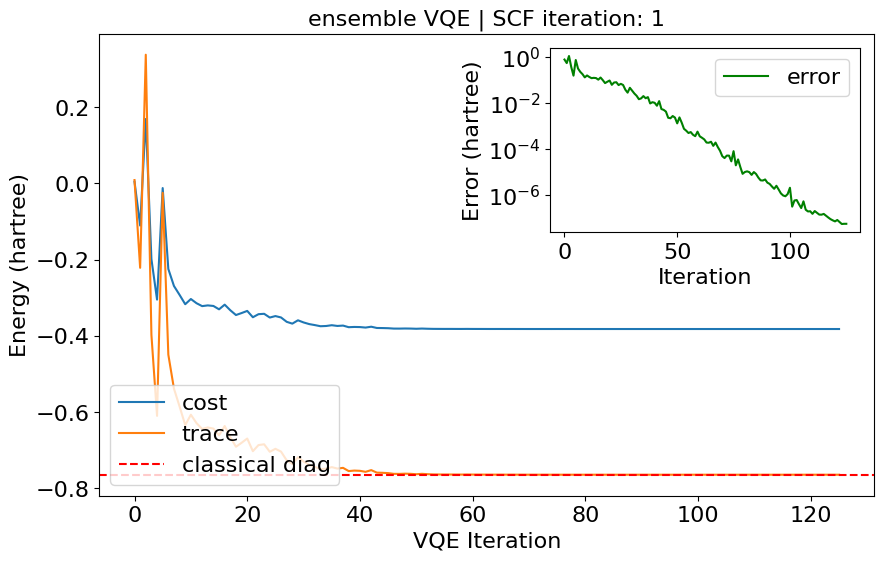

Energy from VQE: -0.7644307464199418 | Error: 5.630276755930197e-08
printing density in OAO basis: 
 [[ 0.4759294   0.23749211  0.43914487  0.01303429]
 [ 0.23749211  0.47620558  0.01285079  0.43916532]
 [ 0.43914487  0.01285079  0.52416984 -0.23749203]
 [ 0.01303429  0.43916532 -0.23749203  0.52369519]]


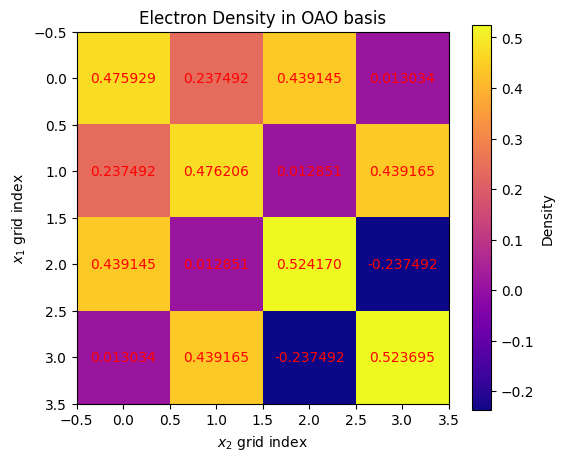

Iter 1: E = -2.16253105 dE = 2.16e+00 dRMS = 5.03e-02
printing density in AO basis: 
 [[ 0.60481811  0.09821931  0.58540701 -0.21308546]
 [ 0.09821931  0.60575231 -0.21361584  0.58543431]
 [ 0.58540701 -0.21361584  0.72817332 -0.53075423]
 [-0.21308546  0.58543431 -0.53075423  0.72689746]]
Printing Hamiltonian: 
 SparsePauliOp(['II', 'IX', 'IZ', 'XI', 'XX', 'XZ', 'YY', 'ZI', 'ZX', 'ZZ'],
              coeffs=[ 1.22335005e-01+0.j, -2.64241578e-01+0.j,  1.09702824e-04+0.j,
 -4.24650602e-01+0.j,  1.04078271e-01+0.j, -3.39437983e-06+0.j,
  3.03167835e-07+0.j,  7.58960404e-02+0.j, -2.39819541e-01+0.j,
 -7.65067942e-05+0.j])
optimized parameters: [ 1.06541642  1.57089466 -0.03285813  3.1417439 ]
Energy from classical diagonalazation: -0.7311991316529722


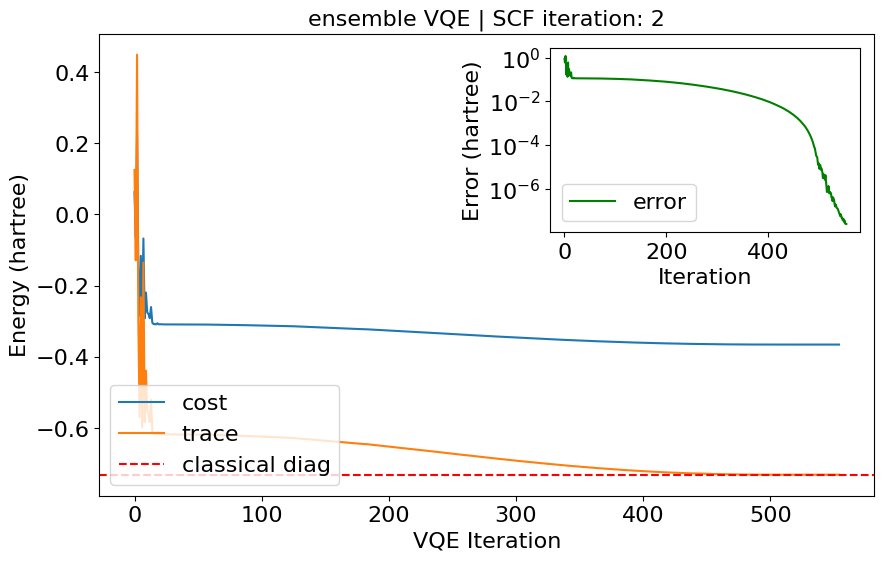

Energy from VQE: -0.731199106003531 | Error: 2.5649441237618475e-08
printing density in OAO basis: 
 [[ 0.48564009  0.24193928  0.43726035  0.00790951]
 [ 0.24193928  0.48561452  0.00799556  0.43725795]
 [ 0.43726035  0.00799556  0.51431229 -0.24193928]
 [ 0.00790951  0.43725795 -0.24193928  0.51443309]]


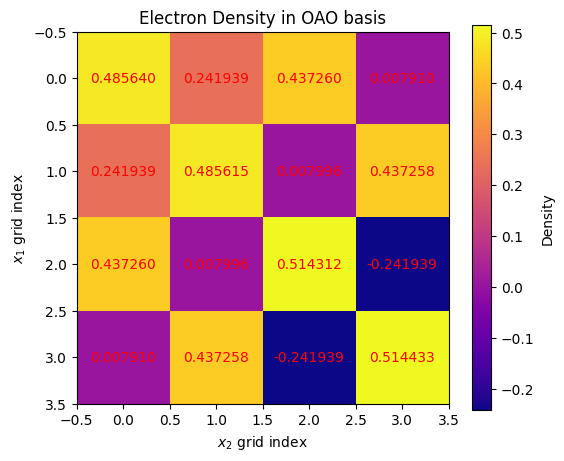

Iter 2: E = -2.16272555 dE = 1.95e-04 dRMS = 9.52e-03
printing density in AO basis: 
 [[ 0.63446385  0.10074528  0.58451564 -0.22788368]
 [ 0.10074528  0.6343812  -0.22762566  0.58451122]
 [ 0.58451564 -0.22762566  0.70454794 -0.53158153]
 [-0.22788368  0.58451122 -0.53158153  0.70486761]]
Printing Hamiltonian: 
 SparsePauliOp(['II', 'IX', 'IZ', 'XI', 'XX', 'XZ', 'YY', 'ZI', 'ZX', 'ZZ'],
              coeffs=[ 1.25014028e-01+0.j, -2.64125366e-01+0.j,  1.61579339e-05+0.j,
 -4.24740074e-01+0.j,  1.03919253e-01+0.j, -1.14040018e-06+0.j,
  3.31309394e-07+0.j,  7.98526176e-02+0.j, -2.39774309e-01+0.j,
 -1.67337610e-05+0.j])
optimized parameters: [ 1.06775161  1.57082847 -0.04074192  3.14137794]
Energy from classical diagonalazation: -0.7262140805020527


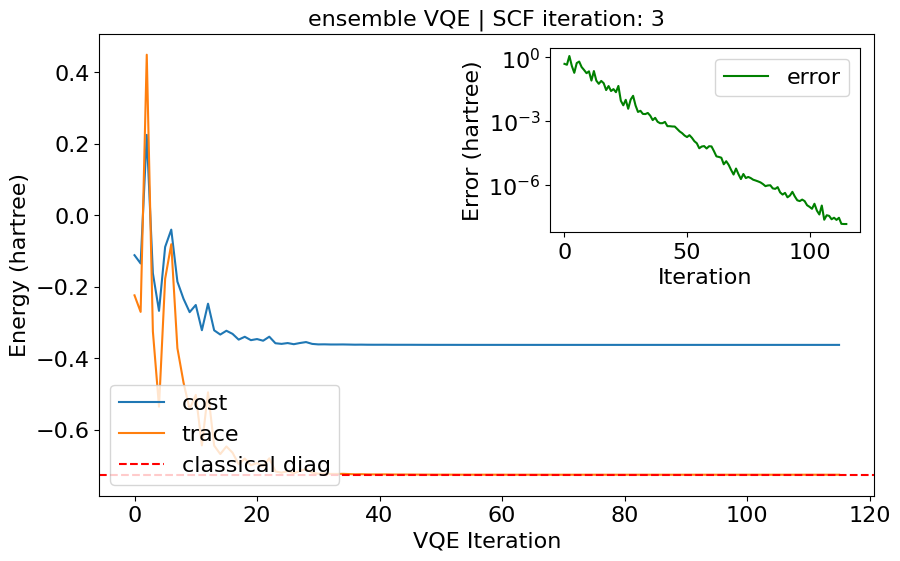

Energy from VQE: -0.726214065813346 | Error: 1.4688706695409337e-08
printing density in OAO basis: 
 [[ 0.4820981   0.24084761  0.43769377  0.00980395]
 [ 0.24084761  0.48221701  0.00983211  0.43769798]
 [ 0.43769377  0.00983211  0.51788641 -0.24084762]
 [ 0.00980395  0.43769798 -0.24084762  0.51779848]]


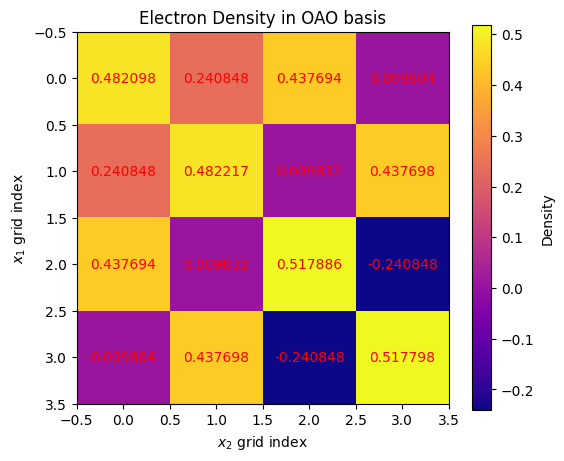

Iter 3: E = -2.16281481 dE = 8.93e-05 dRMS = 5.60e-03
printing density in AO basis: 
 [[ 0.62279507  0.10176085  0.58398115 -0.2221212 ]
 [ 0.10176085  0.62321303 -0.22203002  0.58397707]
 [ 0.58398115 -0.22203002  0.71371898 -0.53288857]
 [-0.2221212   0.58397707 -0.53288857  0.71348336]]
Printing Hamiltonian: 
 SparsePauliOp(['II', 'IX', 'IZ', 'XI', 'XX', 'XZ', 'YY', 'ZI', 'ZX', 'ZZ'],
              coeffs=[ 1.25007329e-01+0.j, -2.64121685e-01+0.j,  3.54956203e-06+0.j,
 -4.24744635e-01+0.j,  1.03918349e-01+0.j, -1.58615715e-06+0.j,
  6.97012808e-07+0.j,  7.98906623e-02+0.j, -2.39770951e-01+0.j,
 -1.59319007e-05+0.j])
optimized parameters: [ 2.07388288e+00  1.57090525e+00 -4.08431219e-02  2.97698619e-04]
Energy from classical diagonalazation: -0.7262349759109422


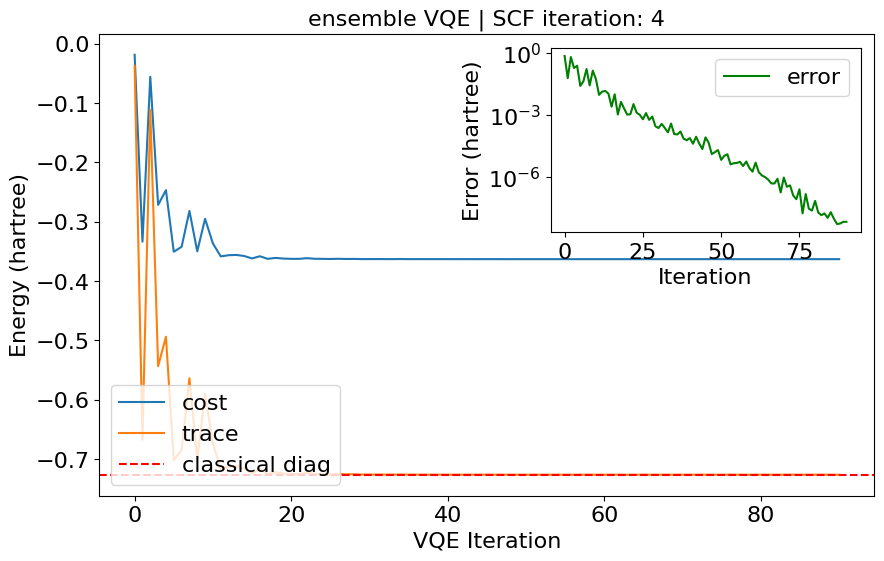

Energy from VQE: -0.7262349688313366 | Error: 7.079605568449665e-09
printing density in OAO basis: 
 [[ 0.48215912  0.24086493  0.43768692  0.00979544]
 [ 0.24086493  0.48206822  0.00989086  0.43768106]
 [ 0.43768692  0.00989086  0.51778836 -0.24086492]
 [ 0.00979544  0.43768106 -0.24086492  0.51798429]]


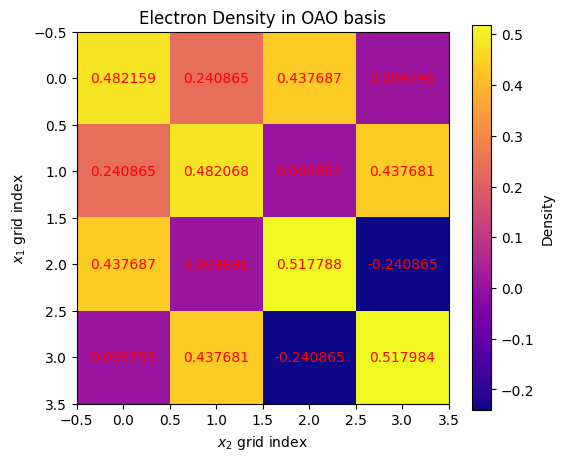

Iter 4: E = -2.16281479 dE = 1.98e-08 dRMS = 8.97e-05
printing density in AO basis: 
 [[ 0.62296877  0.10189004  0.58391616 -0.22212117]
 [ 0.10189004  0.62266031 -0.22183922  0.5839102 ]
 [ 0.58391616 -0.22183922  0.7134943  -0.53299788]
 [-0.22212117  0.5839102  -0.53299788  0.7140158 ]]
SCF Converged at iteration 4, Energy = -2.16281479 Ha


In [20]:
Energy_total = []
vqe_cost = []
vqe_tr = []
for SCF_ITER in range(1, SCF_maxiter + 1):
    F_AO = mf.get_fock(dm=D_AO)
    # DIIS error matrix
    diis_e = np.einsum('ij,jk,kl->il', F_AO, D_AO, S_AO) - np.einsum('ij,jk,kl->il', S_AO, D_AO, F_AO)
    diis_e = S_sqrt_inv @ diis_e @ S_sqrt_inv
    if SCF_ITER > 1:
        F_list.append(F_AO)
        DIIS_error.append(diis_e)
    dRMS = np.mean(diis_e ** 2) ** 0.5

    # DIIS extrapolation
    if SCF_ITER > 1:
        diis_count = len(F_list)
        B = np.empty((diis_count + 1, diis_count + 1))
        B[-1, :] = -1
        B[:, -1] = -1
        B[-1, -1] = 0

        for num1, e1 in enumerate(DIIS_error):
            for num2, e2 in enumerate(DIIS_error):
                if num2 > num1: continue
                val = np.einsum('ij,ij->', e1, e2)
                B[num1, num2] = val
                B[num2, num1] = val

        # normalize
        B[:-1, :-1] /= np.abs(B[:-1, :-1]).max()

        # Build residual vector, [Pulay:1980:393], Eqn. 6, RHS
        resid = np.zeros(diis_count + 1)
        resid[-1] = -1

        # Solve Pulay equations, [Pulay:1980:393], Eqn. 6

        ci = np.linalg.solve(B, resid)

        # Calculate new fock matrix as linear
        # combination of previous fock matrices
        F_AO = np.zeros_like(F_AO)
        for num, c in enumerate(ci[:-1]):
            F_AO += c * F_list[num]

    # Transform to orthogonal AO basis
    F_OAO = S_sqrt_inv @ F_AO @ S_sqrt_inv
    eps, C_OAO = np.linalg.eigh(F_OAO)

    H_qubit, IJ_op_list, full_pauliop_list, full_pauli_list = transformation_Hmatrix_Hqubit(F_OAO, n_qubits)
    print(f"Printing Hamiltonian: \n {H_qubit}")
    params = np.random.rand(4)
    Ham = H_qubit.to_matrix()
    res = sp.optimize.minimize(cost_function_statevector, x0=params, args=(Ham), method='COBYLA', callback=lambda p:_callback(p, Ham))

    full_paul_dic = {}
    for size in range(len(full_pauliop_list)):
        full_paul_dic[f"{full_pauliop_list[size].paulis[0]}"] = float(full_pauliop_list[size].coeffs.real[0])

    optimized_parameters = res.x
    print(f"optimized parameters: {optimized_parameters}")
    n_occ = n_orbs//2
    print(f"Energy from classical diagonalazation: {np.sum(eps[:2])}")
    plot_vqe(vqe_cost, vqe_tr, np.sum(eps[:2]), SCF_ITER)
    processors = circuit(2, 2, layers=1, lp=optimized_parameters)

    trH = 0.
    for state in range(n_occ):
        trH += mesurements(Ham, processors[state])
    print(f"Energy from VQE: {trH} | Error: {trH - np.sum(eps[:2])}")
    all_exp_values = np.zeros((n_occ, len(full_pauliop_list)))
    for state in range(n_occ):
        for pauli in range(len(full_pauliop_list)):
               all_exp_values[state, pauli] = mesurements(full_pauliop_list[pauli].to_matrix(), processors[state])


    product_coeff = np.zeros((n_occ, n_orbs * (n_orbs + 1) // 2))

    for occ in range(n_occ):
        for ij in range(len(IJ_op_list)):
            for pauli in IJ_op_list[ij]:
                product_coeff[occ, ij] += pauli.coeffs[0] * all_exp_values[
                    occ, full_pauli_list.index(Pauli(pauli.paulis))] / 2.

    # Compute the density matrix
    D_OAO = np.zeros((n_orbs, n_orbs))
    for i in range(n_orbs):
        for j in range(i + 1):
            for occ in range(n_occ):
                ij = i * (i + 1) // 2 + j
                D_OAO[i, j] += product_coeff[occ, ij]
            D_OAO[j, i] = D_OAO[i, j]
    print("printing density in OAO basis: \n", D_OAO)
    plot_density(D_OAO)
    D_AO[:] = S_sqrt_inv @ D_OAO @ S_sqrt_inv
    D_AO_new = 2 * D_AO
    # Compute total energy
    E_T = np.einsum('pq,pq->', D_AO_new, AO_kinetic)
    E_V = np.einsum('pq,pq->', D_AO_new, AO_potential)
    Exc = mf.energy_elec(dm=D_AO_new)[1]  # E_Hartree + E_XC
    Etot_new = E_T + E_V + Exc + E_nuc

    Delta_E = abs(Etot_new - Etot)


    print(f"Iter {SCF_ITER}: E = {Etot_new:.8f} dE = {Delta_E:.2e} dRMS = {dRMS:.2e}")

    Etot = Etot_new
    Energy_total.append(Etot)
    D_AO = D_AO_new
    vqe_cost.clear()
    vqe_tr.clear()
    print("printing density in AO basis: \n", D_AO)

    if Delta_E < E_conv and dRMS < D_conv:
        print(f"SCF Converged at iteration {SCF_ITER}, Energy = {Etot:.8f} Ha")
        break
    if SCF_ITER == SCF_maxiter:
        print(f"SCF is not converged, Energy = {Etot:.8f} Ha")

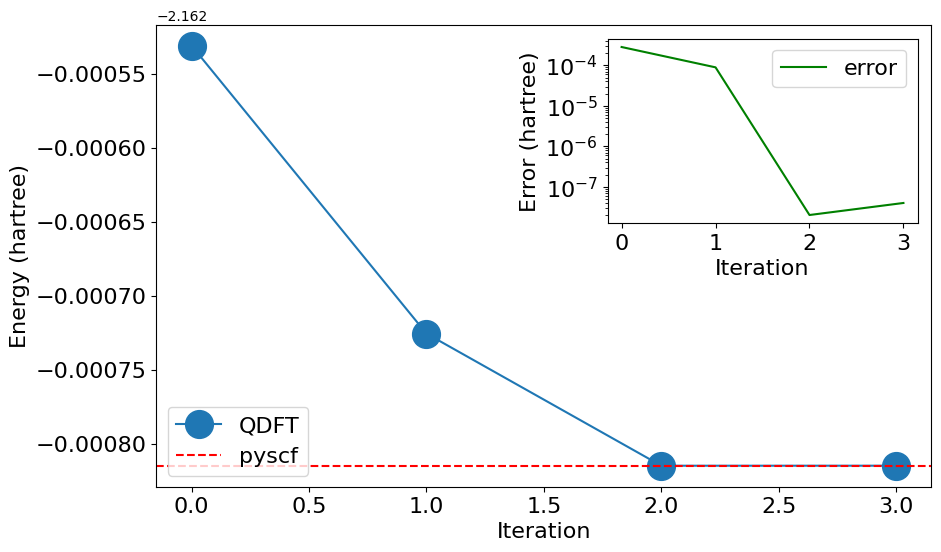

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(Energy_total, marker="o", ms=20, label="QDFT")
ax.axhline(y=mf.energy_tot(), ls="--", color="red", label="pyscf")
ax.set_ylabel('Energy (hartree)', fontsize=16)
ax.set_xlabel('Iteration', fontsize=16)
ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16, loc="lower left")
sub_ax = inset_axes(
    parent_axes=ax,
    width="40%",
    height="40%",
    borderpad=1  # padding between parent and inset axes
)
sub_ax.plot(Energy_total - mf.energy_tot(), color="green", label="error")
sub_ax.set_yscale('log')
sub_ax.set_ylabel('Error (hartree)', fontsize=16)
sub_ax.set_xlabel('Iteration', fontsize=16)
sub_ax.tick_params(axis='both', labelsize=16)
sub_ax.legend(fontsize=16)
plt.show()